# Vectors, matrices, and linear algebra with NumPy

This notebook uses one small feature matrix to make shapes and core linear-algebra operations visible. Run the cells from top to bottom.

## Load the shared fixture

The helper keeps file loading and plot construction out of the learning flow. Every numerical operation below uses NumPy directly.

In [8]:
import numpy as np

from python_helpers import load_fixture_tables, matrix_multiplication_plot

TOLERANCE = 1e-6
tables = load_fixture_tables()

feature_names = tables["features"].columns[1:].tolist()
coefficient_names = tables["coefficients"]["feature"].tolist()
assert coefficient_names == feature_names

X = tables["features"][feature_names].to_numpy(dtype=np.float64)
beta = tables["coefficients"]["coefficient"].to_numpy(dtype=np.float64)
A = tables["system"][["a1", "a2"]].to_numpy(dtype=np.float64)
b = tables["system"]["b"].to_numpy(dtype=np.float64)
expected = dict(zip(tables["expected"]["name"], tables["expected"]["value"]))

## Inspect shapes

`X` has three observations and two features. `beta` has one coefficient for each feature, so `X @ beta` is valid.

In [9]:
print(f"feature order: {feature_names}")
print(f"X: shape={X.shape}, dtype={X.dtype}")
print(f"beta: shape={beta.shape}, dtype={beta.dtype}")
print(f"X.T: shape={X.T.shape}")
X, beta

feature order: ['feature_1', 'feature_2']
X: shape=(3, 2), dtype=float64
beta: shape=(2,), dtype=float64
X.T: shape=(2, 3)


(array([[1., 2.],
        [3., 4.],
        [5., 6.]]),
 array([ 0.5, -1. ]))

## Multiply a matrix by a vector

The matching inner dimensions disappear. The outer dimension—three observations—determines the three prediction values.

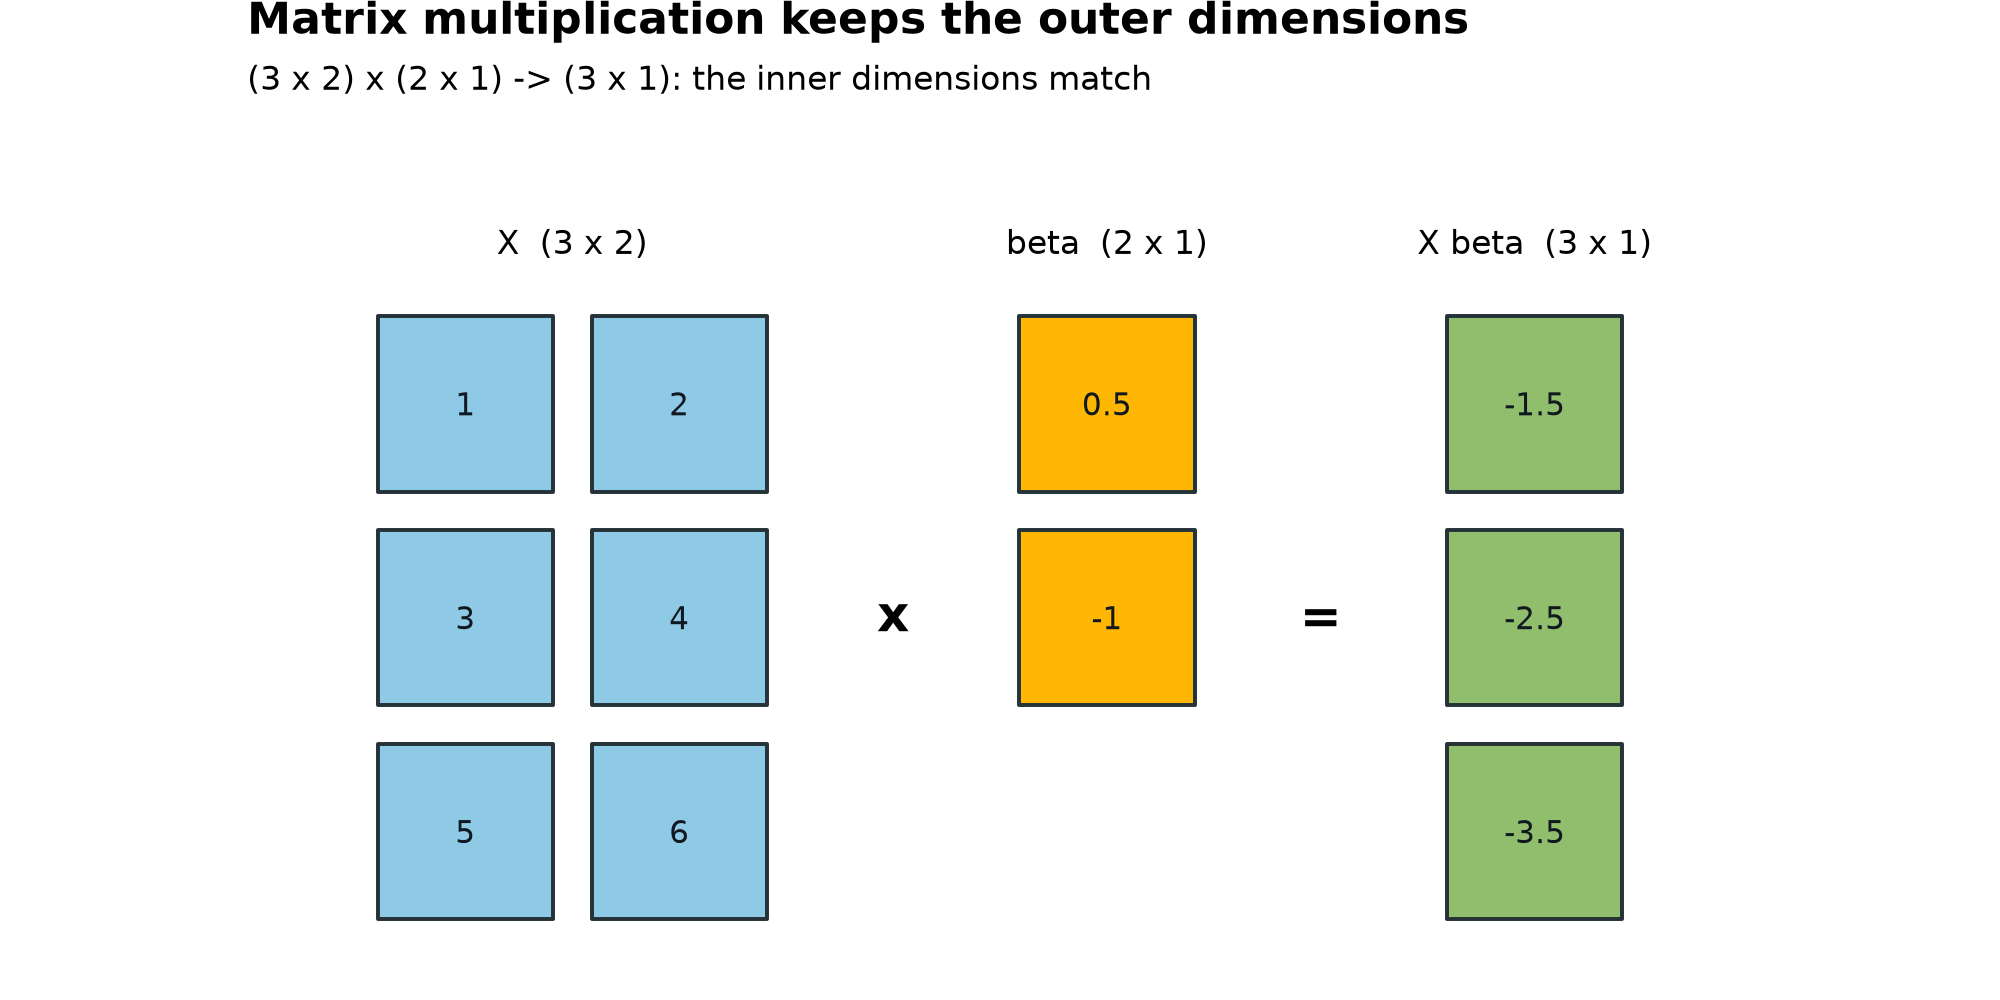

In [10]:
predictions = X @ beta
matrix_multiplication_plot(X, beta, predictions)

## Compute the core operations

A dot product produces one number, a norm measures vector length, and `X.T @ X` compares every feature with every feature. The final expression solves a separate two-equation system.

In [11]:
first_row_dot = X[0] @ beta
coefficient_norm = np.linalg.norm(beta)
gram_matrix = X.T @ X
system_solution = np.linalg.solve(A, b)

print(f"first row dot beta: {first_row_dot:g}")
print(f"beta norm: {coefficient_norm:.12f}")
print(f"predictions: {predictions}")
print(f"X.T @ X:\n{gram_matrix}")
print(f"linear-system solution: {system_solution}")

first row dot beta: -1.5
beta norm: 1.118033988750
predictions: [-1.5 -2.5 -3.5]
X.T @ X:
[[35. 44.]
 [44. 56.]]
linear-system solution: [2. 3.]


In [12]:
expected_predictions = np.array([expected[f"prediction_{i}"] for i in range(1, 4)])
expected_gram = np.array([
    [expected["gram_11"], expected["gram_12"]],
    [expected["gram_21"], expected["gram_22"]],
])
expected_solution = np.array([expected["solution_1"], expected["solution_2"]])

np.testing.assert_allclose(first_row_dot, expected["first_row_dot"], rtol=TOLERANCE, atol=TOLERANCE)
np.testing.assert_allclose(coefficient_norm, expected["coefficient_norm"], rtol=TOLERANCE, atol=TOLERANCE)
np.testing.assert_allclose(predictions, expected_predictions, rtol=TOLERANCE, atol=TOLERANCE)
np.testing.assert_allclose(gram_matrix, expected_gram, rtol=TOLERANCE, atol=TOLERANCE)
np.testing.assert_allclose(system_solution, expected_solution, rtol=TOLERANCE, atol=TOLERANCE)
print("The NumPy results match the shared reference.")

The NumPy results match the shared reference.


## Broadcasting and shape errors

NumPy can add the length-two vector to every row of `X`. Matrix multiplication is stricter: a length-three coefficient vector is incompatible with the two columns of `X`.

In [13]:
broadcast_sum = X + beta
expected_broadcast_sum = np.array([[1.5, 1.0], [3.5, 3.0], [5.5, 5.0]])
np.testing.assert_allclose(broadcast_sum, expected_broadcast_sum)
broadcast_sum

array([[1.5, 1. ],
       [3.5, 3. ],
       [5.5, 5. ]])

In [14]:
try:
    X @ np.array([0.5, -1.0, 2.0])
except ValueError as error:
    print(f"Expected incompatible-shape error: {str(error).splitlines()[0]}")
else:
    raise AssertionError("The incompatible-shape example did not fail.")

print("All T02 NumPy checks passed.")

Expected incompatible-shape error: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 2)
All T02 NumPy checks passed.
